# Лабораторная работа № 2 — обеспечение качества данных

**Дисциплина:** Визуализация и моделирование

Решение выполнено на исходном наборе вакансий Monster.com с помощью Pandas, регулярных выражений и Matplotlib. Исходные столбцы сохраняются: обработанные значения добавляются в отдельные поля, чтобы можно было сравнить результат с оригиналом.

**Выполнил:** Аникин Максим  
**Поток:** ___


**Цель работы:** исследование и обработка данных для повышения их качества.

**Краткое описание:** в лабораторной работе приводится поэтапный план изучения и обработки намеренно не предобработанных данных. Необходимо выполнить все этапы плана и оценить результаты преобразований.

# Данные



В папке [Data/lab3](https://drive.google.com/drive/folders/1437z7m5Ut4WUJOhJg1oZz13dtBpxgFKs?usp=share_link) расположена таблица `monster_com_job_sample.com` с данными о вакансиях. Также эти данные с описанием и примерами обработки можно найти на [kaggle](https://www.kaggle.com/code/ankkur13/perfect-dataset-to-get-the-hands-dirty/data#).

##### **Формат данных**

```
country,country_code,date_added,has_expired,job_board,job_description,job_title,job_type,location,organization,page_url,salary,sector,uniq_id
United States of America,US,"",No,jobs.monster.com,"TeamSoft is seeing an IT Support Specialist to join our client in Madison, WI. The ideal candidate must have at least 6 years of experience in the field. They need to be familiar with a variety of the field's concepts, practices, and procedures as this position relies on extensive experience and judgment to plan and accomplish goals. Required Skills:вАҐ Call tracking softwareвАҐ Phone based technical supportвАҐ Problem documentation and communicationвАҐ Remote Desktop Management ToolsвАҐ Respond to customer requestsвАҐ General understanding of LANDeskвАҐ Microsoft Office 2007 SuiteFind out why TeamSoft is the Madison area's technology leader with over 200 IT consultants. Owned, operated, and managed by IT consultants, TeamSoft is the clear choice for your career. Join the TeamSoft family today!Did you know?вАҐ TeamSoft offers salaried options for many positions that include 5 weeks PTO and great benefits!вАҐ TeamSoft has been in business since 1996вАҐ TeamSoft's owners are local IT professionals who possess a wealth of experience in application development, business analysis, and project managementвАҐ TeamSoft's Recruiters are knowledgeable, friendly, and ready to help you make your next great career moveвАҐ TeamSoft offers a full benefits suite to all of our W2 consultants, including a 401k plan with a 100% vested 4% dollar for dollar matchвАҐ Our targeted selection process is designed to get to know your strengths and career interests and provide you with the best chance for success in your new positionвАҐ Our longest running consultant has been with us for 16 yearsвАҐ Consultants can participate in our charitable giving committee. To date, TeamSoft's charitable giving committee has donated over $100,000!TeamSoft is owned by local IT professionals. Our team also has deep experience with IT staffing. Our clients understand this and rely on our expertise. That is why TeamSoft is the Madison Area's largest privately owned IT consulting firm, with more than 200 current consultants! With over 50 active clients, TeamSoft will give you the greatest exposure to the widest range of IT careers.Our owners possess a combined 60+ years of IT consulting experience. Our recruiting and Account Management staff are very well-versed in our client markets. We get you. We know you. We know what you do every day. And we know what you deal with on the job.You take your career seriously and so do we. At TeamSoft you are not just a resume or number. Our goal is to create long-term partnerships with each of our consultants, and according to feedback from many of them, we are very good at this. Click HERE to see what our consultants have to say about working with TeamSoft.TeamSoft -- Promote yourself!TeamSoft is an equal employment opportunity employer functioning under an Affirmative Action Plan.",IT Support Technician Job in Madison,Full Time Employee,"Madison, WI 53702","",http://jobview.monster.com/it-support-technician-job-madison-wi-us-167855963.aspx?mescoid=1500134001001&jobPosition=20,"",IT/Software Development,11d599f229a80023d2f40e7c52cd941e
United States of America,US,"",No,jobs.monster.com,"The Wisconsin State Journal is seeking a flexible and motivated reporter/editor to lead its three-person business desk. WeвАЩre looking for an experienced journalist able to spot trends, be a watchdog and reflect the Madison areaвАЩs vibrant entrepreneurial community. This is a hybrid reporting and editing position that calls for a fleet-footed, multimedia storyteller able to maximize the newspaperвАЩs online presentation while also editing two sections a week. Candidates must have strong news judgment, be well versed in business news and trends and be able to quickly prioritize coverage.At least five yearsвАЩ experience reporting or editing for digital and print platforms desired. To be considered for the position, applicants must apply online.¬†As part of your online application, please attach five samples of your work or links to five recent stories.Wisconsin State Journal, 1901 Fish Hatchery Road, Madison, WI 53713Affirmative Action/Equal Opportunity Employer/Pre-employment drug testing appliesPI94338362Apply Here",Business Reporter/Editor Job in Madison,Full Time,"Madison, WI 53708",Printing and Publishing,http://jobview.monster.com/business-reporter-editor-job-madison-wi-us-167830105.aspx?mescoid=2700437001001&jobPosition=7,"","",e4cbb126dabf22159aff90223243ff2a
...
```

##### **Описание полей**
- `country` — наименование страны;
- `country_code` — код страны;
- `date_added` — дата размещения вакансии;
- `has_expired` — актуальность вакансии;
- `job_board` — агрегатор вакансий, с которого собраны данные;
- `job_description` — описание вакансии;
- `job_title` — наименование должности;
- `job_type` — вид занятости;
- `location` — местоположение организации;
- `organization` — наименование организации;
- `page_url` — ссылка на страницу с вакансией;
- `salary` — заработная плата;
- `sector` — сфера деятельности;
- `uniq_id` — уникальный идентификатор записи о вакансии.


# Понимание данных

In [1]:
import re
from pathlib import Path
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)
plt.rcParams["figure.figsize"] = (10, 4)

# Сначала ищем CSV рядом с блокнотом и в стандартных папках Colab.
file_name = "monster_com-job_sample.csv"
local_candidates = [
    Path(file_name),
    Path("monster_com_job_sample.csv"),
    Path("/mnt/data/monster_com_job_sample.csv"),
    Path("/content/drive/MyDrive/Data/lab3") / file_name
]
data_file = next((path for path in local_candidates if path.exists()), None)

# Если файла нет, пробуем скачать набор с Kaggle.
if data_file is None:
    url = "https://www.kaggle.com/api/v1/datasets/download/PromptCloudHQ/us-jobs-on-monstercom"
    try:
        print("CSV не найден. Пробуем скачать исходный набор...")
        urllib.request.urlretrieve(url, "monster_jobs_download.zip")
        with zipfile.ZipFile("monster_jobs_download.zip") as archive:
            csv_files = [name for name in archive.namelist() if name.lower().endswith(".csv")]
            if not csv_files:
                raise ValueError("В архиве нет CSV-файла.")
            archive.extract(csv_files[0], ".")
            data_file = Path(csv_files[0])
    except Exception as error:
        print("Автоматическая загрузка не сработала:", str(error)[:160])
        try:
            from google.colab import files
            print("Загрузите файл monster_com-job_sample.csv вручную.")
            uploaded = files.upload()
            uploaded_files = [Path(name) for name in uploaded if name.lower().endswith(".csv")]
            if uploaded_files:
                data_file = uploaded_files[0]
        except ImportError:
            pass

if data_file is None:
    raise FileNotFoundError(
        "Не найден monster_com-job_sample.csv. Загрузите исходный CSV из папки курса или Kaggle."
    )

df = pd.read_csv(data_file, low_memory=False)

required_columns = [
    "country", "country_code", "date_added", "has_expired", "job_board",
    "job_description", "job_title", "job_type", "location", "organization",
    "page_url", "salary", "sector", "uniq_id"
]
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError("В CSV отсутствуют обязательные столбцы: " + ", ".join(missing_columns))

print("Источник:", data_file)
print("Размер набора:", df.shape)

Источник: monster_com_job_sample.csv
Размер набора: (22000, 14)


В датасете есть несколько столбцов, в каждой ячейке которых записано одно и то же значение. Есть столбцы, в которых формат записи значений не стандартизирован. А есть такие, где указана информация, не соответствующая названию столбца.

**Первый этап изучения данных** – понять, какие основные проблемы предстоит решить для каждого из столбцов. Для этого загрузите датасет и выведите случайные несколько строк из него. Постарайтесь понять, что из себя представляют данные в столбцах.

In [2]:
display(df.sample(min(5, len(df)), random_state=42))

print("Размер набора:", df.shape)
print("Типы столбцов:")
print(df.dtypes.to_string())

,country,country_code,date_added,has_expired,job_board,job_description,job_title,job_type,location,organization,page_url,salary,sector,uniq_id
13035,United States of America,US,NaN,No,jobs.monster.com,The QC Lead position requires an understanding of food science and food/dietary supple...,Quality Control Lead Job in Santa Cruz,Full Time,"Santa Cruz, CA 95060",Manufacturing - Other,http://jobview.monster.com/Quality-Control-Lead-Job-Santa-Cruz-CA-US-164370398.aspx?me...,NaN,Experienced (Non-Manager),c44af81ceb38d2b6fe00baf15d0dffe6
3115,United States of America,US,NaN,No,jobs.monster.com,JOB DESCRIPTION DEPARTMENT: ...,Case Manager Job in Sunset Point,Full Time Employee,"Sunset Point, FL 33765",Healthcare Services,http://jobview.monster.com/Case-Manager-Job-Sunset-Point-FL-US-166104158.aspx?mescoid=...,NaN,Medical/Health,217600308ffc96a1a81eb8afba5ee522
8732,United States of America,US,NaN,No,jobs.monster.com,POSITION PURPOSE The Senior Manager Foundation PR will be responsible for driving comm...,Sr Manager,Full Time,"Atlanta, GA 30301",Retail,http://jobview.monster.com/sr-manager-foundation-pr-job-atlanta-ga-us-170527238.aspx?m...,NaN,Manager (Manager/Supervisor of Staff),ef7db9ba10dd8bf7754ecf6ddd09a5aa
7591,United States of America,US,NaN,No,jobs.monster.com,"GroundskeeperWest Knox Apart need a F/T Groundskeeper. Duties - clean breezeways, hall...",Groundskeeper Job in Knoxville,Full Time,"Knoxville, TN 37923",NaN,http://jobview.monster.com/Groundskeeper-Job-Knoxville-TN-US-166981535.aspx?mescoid=37...,NaN,NaN,cd3adb94fc647ca5ea3af731dc1da065
221,United States of America,US,NaN,No,jobs.monster.com,"Combined Insurance is seeking Sales Agents to join our fast-paced, high energy, growin...",Sales Agent Job in Knoxville,Full Time,"Knoxville, TN",Insurance,http://jobview.monster.com/Sales-Agent-Job-Knoxville-TN-US-166279908.aspx?mescoid=4100...,NaN,NaN,ec59e3f419b851259632b757183d7365


Размер набора: (22000, 14)
Типы столбцов:
country            object
country_code       object
date_added         object
has_expired        object
job_board          object
job_description    object
job_title          object
job_type           object
location           object
organization       object
page_url           object
salary             object
sector             object
uniq_id            object


**Первичная таблица проблем по столбцам.** Все 14 полей исходного CSV при загрузке имеют тип `object`, то есть представлены строками. Это ожидаемо для такого набора: даже даты и зарплаты записаны в текстовом виде.

| Поле | Тип в Pandas | Замечания для проверки |
|---|---|---|
| `country` | object | В непустых ячейках одно значение — страна США. |
| `country_code` | object | В непустых ячейках один код `US`. |
| `date_added` | object | Почти все значения пустые; дату нужно было бы преобразовать отдельно. |
| `has_expired` | object | В непустых ячейках одно значение `No`. |
| `job_board` | object | Указан один источник — `jobs.monster.com`. |
| `job_description` | object | Длинный свободный текст; в отдельных строках копируется в другие поля. |
| `job_title` | object | Свободный текст; иногда содержит город или штат. |
| `job_type` | object | Разные разделители и написание; есть пропуски и неполные значения. |
| `location` | object | Город, штат и индекс записаны в разных сочетаниях; иногда вместо адреса находится описание вакансии. |
| `organization` | object | Есть пропуски; в некоторых строках значение совпадает с `sector`. |
| `page_url` | object | Ссылки на вакансии; в этом наборе значения уникальны. |
| `salary` | object | Большая часть значений пустая; суммы, диапазоны и периоды смешаны в одной строке. |
| `sector` | object | Есть пропуски; иногда встречается значение, совпадающее с работодателем. |
| `uniq_id` | object | По описанию это уникальный идентификатор; проверяем это отдельно. |

Точные количества пропусков, уникальных значений и совпадений рассчитываются в следующих ячейках на полном CSV.


### Оценка пустых ячеек в датасете

Выясните, в каких столбцах, строках и в каком количестве отсутствуют данные:
1. С помощью модуля `pandas` составьте таблицу, где каждому названию столбца будет сопоставлено общее количество ячеек и количество пустых ячеек.
2. Подсчитайте количество строк датасета, в которых пустыми являются более 75% ячеек.
3. Визуализируйте число пропусков в датасете с помощью модуля, построив столбчатую диаграмму. Для удобства можно воспользоваться модулем `missingno`.


,всего ячеек,пустых ячеек,непустых ячеек,"доля пропусков, %"
date_added,22000,21878,122,99.45
salary,22000,18557,3443,84.35
organization,22000,6867,15133,31.21
sector,22000,5194,16806,23.61
job_type,22000,1628,20372,7.4
country,22000,0,22000,0.0
country_code,22000,0,22000,0.0
has_expired,22000,0,22000,0.0
job_board,22000,0,22000,0.0
job_description,22000,0,22000,0.0


Строк, где более 75% ячеек пустые: 0


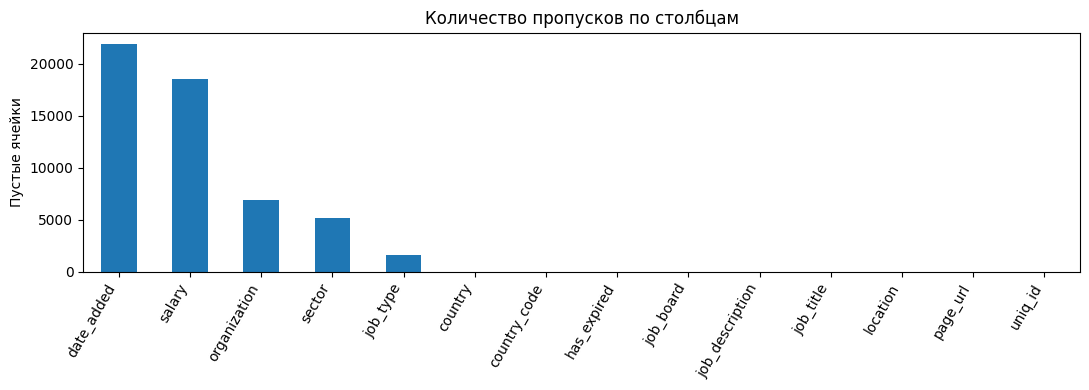

In [3]:
# Считаем пустыми как NaN, так и строки, состоящие только из пробелов.
missing_mask = df.isna() | df.apply(
    lambda column: column.astype("string").str.fullmatch(r"\s*", na=False)
)

missing_info = pd.DataFrame({
    "всего ячеек": len(df),
    "пустых ячеек": missing_mask.sum(),
    "непустых ячеек": len(df) - missing_mask.sum(),
    "доля пропусков, %": (missing_mask.mean() * 100).round(2)
}).sort_values("пустых ячеек", ascending=False)

display(missing_info)

rows_over_75 = int((missing_mask.mean(axis=1) > 0.75).sum())
print("Строк, где более 75% ячеек пустые:", rows_over_75)

missing_counts = missing_mask.sum().sort_values(ascending=False)
ax = missing_counts.plot(kind="bar", figsize=(11, 4))
ax.set_title("Количество пропусков по столбцам")
ax.set_ylabel("Пустые ячейки")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

Проверьте, как изменится размер датасета, если принять решение удалить все строки, где есть пустые значения. Сделайте выводы.

In [4]:
# Удаляем строки, в которых есть хотя бы одна пустая ячейка.
all_complete = df.loc[~missing_mask.any(axis=1)].copy()

removed_rows = len(df) - len(all_complete)
removed_percent = removed_rows / len(df) * 100 if len(df) else 0

print("Было строк:", len(df))
print("Останется после удаления всех строк с пропусками:", len(all_complete))
print("Потеряно строк:", removed_rows)
print(f"Доля потерянных строк: {removed_percent:.2f}%")

print(
    "Вывод: полное удаление строк с пропусками здесь не подходит. "
    "Оно оставляет слишком мало вакансий, поэтому дальше обрабатываем отдельные столбцы."
)

Было строк: 22000
Останется после удаления всех строк с пропусками: 5
Потеряно строк: 21995
Доля потерянных строк: 99.98%
Вывод: полное удаление строк с пропусками здесь не подходит. Оно оставляет слишком мало вакансий, поэтому дальше обрабатываем отдельные столбцы.


### Первичная оценка данных в столбцах

Изучите данные в столбцах датасета, ответив на следующие вопросы:
1. Есть ли столбцы, в которых встречается всего одно значение? Как их можно использовать в анализе?
2. Есть ли такие значения, которые встречаются более чем в одном столбце?
3. Есть ли столбцы, данные в которых не соответствуют названию столбца?

In [5]:
# Число уникальных значений считаем без пропусков:
# NaN не является отдельным значением столбца.
unique_counts = df.nunique(dropna=True)

single_value_columns = unique_counts[unique_counts == 1].index.tolist()
single_value_info = pd.DataFrame({
    "число уникальных значений": unique_counts[single_value_columns],
    "единственное значение": [
        df[column].dropna().astype(str).iloc[0]
        for column in single_value_columns
    ]
})
print("Столбцы, в которых встречается только одно непустое значение:")
display(single_value_info)

# Проверяем, совпадают ли значения в разных столбцах одной и той же строки.
text_columns = df.select_dtypes(include=["object"]).columns.tolist()
normalized_data = {}

for column in text_columns:
    normalized_data[column] = (
        df[column].astype("string")
        .str.replace("\xa0", " ", regex=False)
        .str.strip()
        .str.lower()
    )

overlap_rows = []

for first_number in range(len(text_columns)):
    first_column = text_columns[first_number]
    for second_number in range(first_number + 1, len(text_columns)):
        second_column = text_columns[second_number]

        same_value = (
            normalized_data[first_column].notna()
            & normalized_data[second_column].notna()
            & normalized_data[first_column].ne("").fillna(False)
            & normalized_data[first_column].eq(normalized_data[second_column]).fillna(False)
        )

        same_count = int(same_value.sum())
        if same_count > 0:
            overlap_rows.append((first_column, second_column, same_count))

overlap_table = pd.DataFrame(
    overlap_rows,
    columns=["первый столбец", "второй столбец", "совпадающих строк"]
).sort_values("совпадающих строк", ascending=False)

print("Совпадения значений между столбцами в одной и той же строке:")
display(overlap_table)

# Показываем примеры двух наиболее заметных проблем.
same_description_location = (
    normalized_data["job_description"].eq(normalized_data["location"]).fillna(False)
)
print("Примеры, где в location записано описание вакансии:")
display(df.loc[same_description_location, ["job_title", "location"]].head(3))

same_organization_sector = (
    normalized_data["organization"].eq(normalized_data["sector"]).fillna(False)
)
print("Примеры совпадений organization и sector:")
display(df.loc[same_organization_sector, ["organization", "sector"]].head(5))

print("Столбцы с единственным значением могут быть полезны для описания источника,")
print("но почти не помогают сравнивать вакансии внутри этого набора.")
print("Совпадение job_description и location показывает, что в location иногда попал текст описания вакансии.")

Столбцы, в которых встречается только одно непустое значение:


,число уникальных значений,единственное значение
country,1,United States of America
country_code,1,US
has_expired,1,No
job_board,1,jobs.monster.com


Совпадения значений между столбцами в одной и той же строке:


,первый столбец,второй столбец,совпадающих строк
1,job_description,location,905
0,job_description,job_title,31
3,organization,sector,23
2,location,organization,16


Примеры, где в location записано описание вакансии:


,job_title,location
45,Respiratory Therapist PRN Nights - Kindred Hospital Medical Center Job in Houston,Respiratory Therapist PRN Nights - Kindred Hospital Medical Center ( Job Number: 26612...
105,Registered Nurse ICU Full Time Days - Kindred Hospital Town and Country Job in Houston,Registered Nurse ICU Full Time Days - Kindred Hospital Town and Country ( Job Number: ...
115,Experienced Registered Nurse-Critical Care/ICU - Float Pool - Kindred Hospitals - Hous...,Experienced Registered Nurse-Critical Care/ICU - Float Pool - Kindred Hospitals - Hous...


Примеры совпадений organization и sector:


,organization,sector
795,Retail,Retail
1121,Retail,Retail
1810,Retail,Retail
2629,Retail,Retail
4006,Retail,Retail


Столбцы с единственным значением могут быть полезны для описания источника,
но почти не помогают сравнивать вакансии внутри этого набора.
Совпадение job_description и location показывает, что в location иногда попал текст описания вакансии.


### Дублирование данных

Для поиска дублирующихся строк выполните следующие действия:
1. В таблице есть столбец `uniq_id`, значения которого, как сказано в описании данных, являются уникальными идентификаторами записей. Проверьте, действительно ли в этом столбце все значения различны.
2. Проверьте, есть ли в таблице другие столбцы, значения которых в каждой строке различны.
3. Если игнорировать столбцы, где все значения различны, найдутся ли такие строки, для которых значения по всем остальным столбцам будут совпадать?

Оцените результаты поиска дубликатов.

In [6]:
# Проверяем заявленную уникальность идентификатора.
unique_id_count = df["uniq_id"].nunique(dropna=True)
unique_id_missing = int(df["uniq_id"].isna().sum())
unique_id_duplicates = int(df["uniq_id"].duplicated().sum())

print("Уникальных uniq_id:", unique_id_count, "из", len(df))
print("Пустых uniq_id:", unique_id_missing)
print("Повторяющихся uniq_id после первого вхождения:", unique_id_duplicates)

# Ищем столбцы, в которых каждое значение непустое и уникальное.
unique_columns = [
    column for column in df.columns
    if df[column].notna().all() and df[column].nunique(dropna=True) == len(df)
]
print("Столбцы с полностью уникальными непустыми значениями:", unique_columns)

# Исключаем эти столбцы и проверяем повторения по всем оставшимся полям.
compare_columns = [column for column in df.columns if column not in unique_columns]

duplicate_mask = df.duplicated(subset=compare_columns, keep=False)
duplicate_rows_count = int(duplicate_mask.sum())
duplicate_extra_count = int(df.duplicated(subset=compare_columns, keep="first").sum())
duplicate_groups_count = int(
    df.loc[duplicate_mask, compare_columns].drop_duplicates().shape[0]
)

print("Столбцов для сравнения после исключения уникальных:", len(compare_columns))
print("Строк, входящих в группы дубликатов:", duplicate_rows_count)
print("Дополнительных повторных строк:", duplicate_extra_count)
print("Групп одинаковых строк:", duplicate_groups_count)

display(df.loc[duplicate_mask, ["job_title", "location", "uniq_id"]].head(10))

Уникальных uniq_id: 22000 из 22000
Пустых uniq_id: 0
Повторяющихся uniq_id после первого вхождения: 0
Столбцы с полностью уникальными непустыми значениями: ['page_url', 'uniq_id']


Столбцов для сравнения после исключения уникальных: 12
Строк, входящих в группы дубликатов: 2078
Дополнительных повторных строк: 1168
Групп одинаковых строк: 910


,job_title,location,uniq_id
17,Pest Control Technician – Field Service Rep (Entry Level) Job in Denver,"Denver, CO",8d8f39de4a07929a92c2e6dd7a72a0af
27,Traveling Customer Training Professional Job in Houston,"Houston, TX 77040",de49594f00f4af8c1e0fbffd85120208
47,Project Manager ( Z ) Job in Houston,"Houston, TX 77034",ac2da666b68583ed3c3cc4eaee869eb1
56,CASHIER Job in Houston,"Houston, TX",bcf70c41acf97ac8024c0b38c6fcaf87
95,Scrum Master Job in Denver,"Denver, CO",5091d726fbce4a824fe6a1d49458ad4a
96,Financial Advisor / Financial Sales Representative- Full Time Sales,"Houston, TX",e52d5e30ecdf97dd64a44f45bfc2032b
114,Event Promotions: Marketing / Advertising / Public Relations Job in Houston,"Houston, TX 77057",4b8d7a4b2f7449a446a423a47fab633c
165,Enrollment Agent I* (-) Job in Denver,"Denver, CO",c76459c6a16425dcf473a4ccf5bdee33
212,Associate,Job Description : Want more than just a job? Join Forever 21’s Retail Operations Team ...,6d8a7d4329b639d0fd01fdae74ad838b
221,Sales Agent Job in Knoxville,"Knoxville, TN",ec59e3f419b851259632b757183d7365


# Практические задания

В этом разделе необходимо обработать значения в трех столбцах датасета: `location`, `salary` и `job_type`. Цель обработки – стандартизировать данные в каждом из столбцов так, чтобы их можно было анализировать.

### Задание 1

В задании 1 необходимо провести обработку столбца `location`.

#### Задание 1.1

В столбце `location` представлена информация о местоположении организации, в которой открыта вакансия. Каждое значение столбца `location` содержит информацию о городе, коде штата и почтовом индексе.

Однако не в каждой строке есть все три характеристики местоположения, а также могут встречаться разные комбинации из них, записанные в виде строки в произвольном порядке и с разными разделителями.

Например, может быть указан только код штата, только название города или только индекс. Могут быть указаны любые две характеристики из трех.

**Формулировка задания:**
1. Определите, какие форматы встречаются.
2. Напишите одно или несколько регулярных выражений для поиска выявленных форматов.
3. Визуализируйте количество найденных форматов на столбчатой или круговой диаграмме. Также покажите на ней количество строк, в которых формат определить не удалось. Какие форматы встречаются чаще всего?

Ознакомиться с теоретическим материалом по работе с регулярными выражениями можно [по ссылке](https://colab.research.google.com/drive/1eFHdmt9OROLEDJRNc2wNmz0gpE1O3sKU?usp=sharing).

,Количество
Формат,
город+штат+индекс,11298
город+штат,7162
город+индекс,322
штат+индекс,22
город,706
штат,231
индекс,254
не распознан,2005
пустое,0


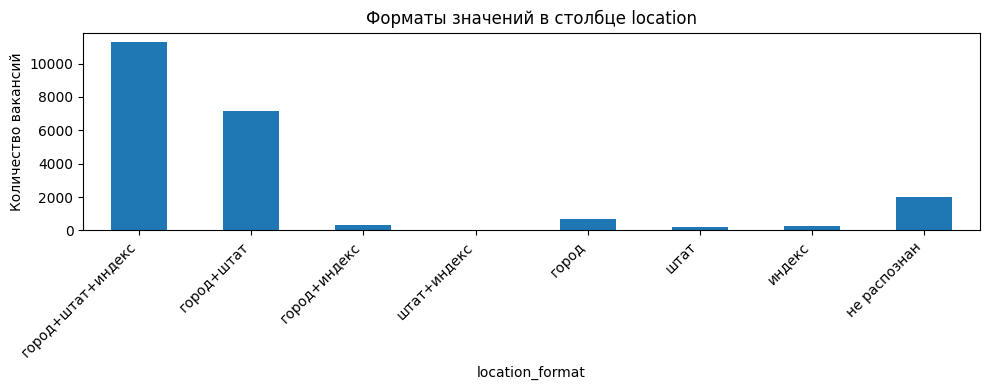

Самый частый формат: город+штат+индекс
Строк, формат которых не удалось определить: 2005


In [7]:
# Список официальных кодов штатов США и округа Колумбия.
state_codes = set(
    "AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS "
    "MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY DC".split()
)

zip_pattern = re.compile(r"(?<!\d)\d{5}(?:-\d{4})?(?!\d)")
state_token_pattern = re.compile(r"(?<![A-Za-z])([A-Za-z]{2})(?![A-Za-z])")
city_pattern = re.compile(r"^[A-Za-zÀ-ÿ][A-Za-zÀ-ÿ .'-]{0,65}$")

invalid_locations = {
    "remote", "anywhere", "unknown", "n/a", "united states",
    "united states of america", "usa", "us", "not specified",
    "multiple locations", "nationwide"
}

def clean_text(value):
    return re.sub(r"\s+", " ", str(value).replace("\xa0", " ")).strip()


def parse_location(value):
    if pd.isna(value) or not clean_text(value):
        return (None, None, None, "пустое")

    text_value = clean_text(value)

    if text_value.lower() in invalid_locations or len(text_value) > 100:
        return (None, None, None, "не распознан")

    text_value = re.sub(
        r"^(?:job\s+)?location\s*:\s*", "", text_value, flags=re.I
    )

    # Находим почтовый индекс. Если их несколько, запись неоднозначна.
    zip_matches = list(zip_pattern.finditer(text_value))
    if len(zip_matches) > 1:
        return (None, None, None, "не распознан")

    zip_code = zip_matches[0].group() if zip_matches else None
    if zip_matches:
        match = zip_matches[0]
        text_value = text_value[:match.start()] + " " + text_value[match.end():]

    # Код штата ищем отдельно от названия города.
    state_matches = []
    for match in state_token_pattern.finditer(text_value):
        token = match.group(1)
        code = token.upper()
        before = text_value[:match.start()].rstrip()

        # Смешанный регистр принимаем только после явного разделителя,
        # чтобы не принять начало названия города La Crosse за штат LA.
        explicit_position = not before or before[-1] in ",;/|"
        if code in state_codes and (token.isupper() or explicit_position):
            state_matches.append((match.start(), match.end(), code))

    if len(state_matches) > 1:
        return (None, None, None, "не распознан")

    state_code = state_matches[0][2] if state_matches else None
    if state_matches:
        start, end, code = state_matches[0]
        text_value = text_value[:start] + " " + text_value[end:]

    city = re.sub(r"\s+", " ", text_value.strip(" ,;/|-")).strip() or None

    if city and (
        not city_pattern.fullmatch(city)
        or city.lower() in invalid_locations
        or len(city.split()) > 6
    ):
        return (None, None, None, "не распознан")

    if not any([city, state_code, zip_code]):
        return (None, None, None, "не распознан")

    format_parts = [
        name for name, part in [
            ("город", city),
            ("штат", state_code),
            ("индекс", zip_code)
        ] if part
    ]

    return (city, state_code, zip_code, "+".join(format_parts))


location_parts = pd.DataFrame(
    df["location"].apply(parse_location).tolist(),
    columns=["city", "state_code", "zip_code", "location_format"],
    index=df.index
)

format_order = [
    "город+штат+индекс", "город+штат", "город+индекс",
    "штат+индекс", "город", "штат", "индекс",
    "не распознан", "пустое"
]
format_counts = location_parts["location_format"].value_counts().reindex(
    format_order, fill_value=0
)

display(format_counts.rename_axis("Формат").to_frame("Количество"))

ax = format_counts[format_counts > 0].plot.bar(figsize=(10, 4))
ax.set_title("Форматы значений в столбце location")
ax.set_ylabel("Количество вакансий")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("Самый частый формат:", format_counts.idxmax())
print("Строк, формат которых не удалось определить:", int(format_counts["не распознан"]))

#### Задание 1.2

В большей части строк удалось извлечь данные из ячейки столбца `location`, но остались и такие, где это не получилось.

1. Вынесите в отдельный датасет записи, в которых не удалось определить формат записи информации о местоположении.
2. Данные о местоположении разделите на 3 столбца: город, код штата, почтовый индекс.

In [8]:
# Сохраняем отдельно строки, в которых формат location определить не удалось.
unrecognized_locations = df.loc[
    location_parts["location_format"].isin(["не распознан", "пустое"])
].copy()

print("Строк с нераспознанным форматом:", len(unrecognized_locations))
display(unrecognized_locations[["job_title", "location"]].head(10))

# Добавляем выделенные части местоположения к исходным данным.
locations = df.copy().join(location_parts)

display(
    locations[
        ["location", "city", "state_code", "zip_code", "location_format"]
    ].head(12)
)

Строк с нераспознанным форматом: 2005


,job_title,location
2,Johnson & Johnson Family of Companies Job Application for Senior Training Leader | Mon...,"DePuy Synthes Companies is a member of Johnson & Johnson's Family of Companies, and is..."
29,Sr. Process Engineer,"Sr. Process Engineer, Manufacturing"
36,RF System Technician,"RF System Technician, Field Service"
45,Respiratory Therapist PRN Nights - Kindred Hospital Medical Center Job in Houston,Respiratory Therapist PRN Nights - Kindred Hospital Medical Center ( Job Number: 26612...
72,"Formulation Scientist Job in ""Statewide""","""Statewide"", CO"
105,Registered Nurse ICU Full Time Days - Kindred Hospital Town and Country Job in Houston,Registered Nurse ICU Full Time Days - Kindred Hospital Town and Country ( Job Number: ...
115,Experienced Registered Nurse-Critical Care/ICU - Float Pool - Kindred Hospitals - Hous...,Experienced Registered Nurse-Critical Care/ICU - Float Pool - Kindred Hospitals - Hous...
135,CH- Helicoptor Repairer Job in Bafb,"Bafb, Aurora 80011"
138,Registered Nurse ICU Full Time Nights - Kindred Hospital Town and Country Job in Houston,Registered Nurse ICU Full Time Nights - Kindred Hospital Town and Country ( Job Number...
188,Assistant Underwriter – Client Services Job in Spokane,"Location: Spokane, WAOverview: Responsible for fulfilling the Company’s service objec..."


,location,city,state_code,zip_code,location_format
0,"Madison, WI 53702",Madison,WI,53702,город+штат+индекс
1,"Madison, WI 53708",Madison,WI,53708,город+штат+индекс
2,"DePuy Synthes Companies is a member of Johnson & Johnson's Family of Companies, and is...",None,None,None,не распознан
3,"Dixon, CA",Dixon,CA,None,город+штат
4,"Camphill, PA",Camphill,PA,None,город+штат
5,"Charlottesville, VA",Charlottesville,VA,None,город+штат
6,Contact name Tony Zerio,Contact name Tony Zerio,None,None,город
7,"Austin, TX 73301",Austin,TX,73301,город+штат+индекс
8,"Austin, TX 78746",Austin,TX,78746,город+штат+индекс
9,"Chesterfield, MO",Chesterfield,MO,None,город+штат


#### Задание 1.3

Рассмотрите отложенную часть выборки (ту, где не удалось данные из столбца `location` разделить на три поля) и сделайте выводы о возможности извлечь из данных город, код штата и почтовый индекс. Извлеките все, что возможно. Что невозможно – оставьте пустым.

In [9]:
# Для сложных записей используем только явные признаки:
# метку Location, фразу located in, конструкцию Job in или контактный адрес.
state_names = {
    "Alabama": "AL", "Alaska": "AK", "Arizona": "AZ", "Arkansas": "AR",
    "California": "CA", "Colorado": "CO", "Connecticut": "CT", "Delaware": "DE",
    "Florida": "FL", "Georgia": "GA", "Hawaii": "HI", "Idaho": "ID",
    "Illinois": "IL", "Indiana": "IN", "Iowa": "IA", "Kansas": "KS",
    "Kentucky": "KY", "Louisiana": "LA", "Maine": "ME", "Maryland": "MD",
    "Massachusetts": "MA", "Michigan": "MI", "Minnesota": "MN",
    "Mississippi": "MS", "Missouri": "MO", "Montana": "MT", "Nebraska": "NE",
    "Nevada": "NV", "New Hampshire": "NH", "New Jersey": "NJ",
    "New Mexico": "NM", "New York": "NY", "North Carolina": "NC",
    "North Dakota": "ND", "Ohio": "OH", "Oklahoma": "OK", "Oregon": "OR",
    "Pennsylvania": "PA", "Rhode Island": "RI", "South Carolina": "SC",
    "South Dakota": "SD", "Tennessee": "TN", "Texas": "TX", "Utah": "UT",
    "Vermont": "VT", "Virginia": "VA", "Washington": "WA",
    "West Virginia": "WV", "Wisconsin": "WI", "Wyoming": "WY",
    "District of Columbia": "DC"
}

state_value_pattern = "|".join(
    sorted(state_codes | set(state_names.keys()), key=len, reverse=True)
)
location_label_pattern = re.compile(r"(?:job\s+)?location\s*:\s*", re.I)
next_field_pattern = re.compile(
    r"(?=(?:overview|description|duration|job\s+description|responsibilities|"
    r"essential\s+job\s+duties|key\s+responsibilities|salary|contract|"
    r"top\s+reasons|date\s+updated|job\s+type|technical\s+expertise)\s*:)",
    re.I
)

place_start_pattern = re.compile(
    rf"^\s*(?P<city>[A-Za-zÀ-ÿ][A-Za-zÀ-ÿ .'-]{{1,55}}?)\s*,\s*"
    rf"(?P<state>{state_value_pattern})"
    rf"(?:\s*\(?\s*(?P<zip>\d{{5}}(?:-\d{{4}})?)\s*\)?)?\s*$",
    re.I
)
city_state_name_pattern = re.compile(
    rf"^\s*(?P<city>[A-Za-zÀ-ÿ][A-Za-zÀ-ÿ .'-]{{1,45}}?)\s+"
    rf"(?P<state>{'|'.join(sorted(state_names.keys(), key=len, reverse=True))})\s*$",
    re.I
)
city_state_code_pattern = re.compile(
    r"^\s*(?P<city>[A-Za-zÀ-ÿ][A-Za-zÀ-ÿ .'-]{1,50}?)\s+(?P<state>[A-Za-z]{2})\s*$",
    re.I
)
zip_only_pattern = re.compile(r"^\s*(?P<zip>\d{5}(?:-\d{4})?)\s*$")
state_only_pattern = re.compile(rf"^\s*(?P<state>{state_value_pattern})\s*$", re.I)
city_only_pattern = re.compile(r"^\s*(?P<city>[A-Za-zÀ-ÿ][A-Za-zÀ-ÿ .'-]{1,55})\s*$")


def state_to_code(state):
    if not state:
        return None
    if state.upper() in state_codes:
        return state.upper()
    return state_names.get(state.title())


def parse_location_chunk(chunk):
    chunk = clean_text(chunk).strip(" ,;/|-")

    if chunk.lower() == "wdc":
        return (None, "DC", None)

    match = place_start_pattern.match(chunk)
    if match:
        return (
            match.group("city").strip(),
            state_to_code(match.group("state")),
            match.group("zip")
        )

    match = city_state_name_pattern.match(chunk)
    if match:
        return (
            match.group("city").strip(),
            state_to_code(match.group("state")),
            None
        )

    match = city_state_code_pattern.match(chunk)
    if match and match.group("state").upper() in state_codes:
        return (
            match.group("city").strip(),
            match.group("state").upper(),
            None
        )

    match = zip_only_pattern.match(chunk)
    if match:
        return (None, None, match.group("zip"))

    match = state_only_pattern.match(chunk)
    if match:
        return (None, state_to_code(match.group("state")), None)

    match = city_only_pattern.match(chunk)
    if match and match.group("city").lower() not in invalid_locations:
        return (match.group("city"), None, None)

    parsed = parse_location(chunk)
    if parsed[3] not in ("не распознан", "пустое"):
        return parsed[:3]

    return (None, None, None)


def is_repeated_city(city):
    if not city:
        return False
    compact_city = city.replace(" ", "")
    middle = len(compact_city) // 2
    return (
        len(compact_city) % 2 == 0
        and compact_city[:middle].lower() == compact_city[middle:].lower()
    )


def recover_location(value):
    if pd.isna(value) or not clean_text(value):
        return (None, None, None, "нет данных")

    text_value = clean_text(value)

    # 1. Сначала ищем явно подписанное поле Location.
    for label in location_label_pattern.finditer(text_value):
        chunk = text_value[label.end():]
        chunk = next_field_pattern.split(chunk, maxsplit=1)[0]

        city, state, zip_code = parse_location_chunk(chunk)
        if any([city, state, zip_code]):
            return (city, state, zip_code, "по явной метке Location")

    # 2. Ищем фразы, прямо указывающие место работы.
    located_match = re.search(
        rf"\b(?:located|based)\s+in\s+(?P<city>[A-Za-zÀ-ÿ][A-Za-zÀ-ÿ .'-]{{1,50}}?)\s*,\s*"
        rf"(?P<state>{state_value_pattern})(?:\s+(?P<zip>\d{{5}}(?:-\d{{4}})?))?(?=[\s.,;]|$)",
        text_value, re.I
    )
    if located_match:
        city = located_match.group("city").strip()
        if not city.lower().startswith(("beautiful ", "upstate ", "greater ", "metro ", "near ")):
            return (
                city,
                state_to_code(located_match.group("state")),
                located_match.group("zip"),
                "по фразе located/based in"
            )

    # 3. В объявлениях агрегатора встречается формат Job in City ZIP, State.
    job_match = re.search(
        rf"\bJob\s+in\s+(?P<city>[A-Za-zÀ-ÿ][A-Za-zÀ-ÿ .'-]{{1,50}}?)\s+"
        rf"(?P<zip>\d{{5}}(?:-\d{{4}})?)\s*,\s*(?P<state>{state_value_pattern})\b",
        text_value, re.I
    )
    if job_match:
        return (
            job_match.group("city").strip(),
            state_to_code(job_match.group("state")),
            job_match.group("zip"),
            "из названия вакансии"
        )

    # 4. В контактном блоке иногда указан адрес. Если город не отделить от улицы,
    # сохраняем только достоверно найденные штат и индекс.
    address_label = re.search(
        r"\bAddress\s*(?::\s*|\s+)(?=(?:PO\s+Box|\d{1,6}\b|[A-Za-z][A-Za-z .'-]{1,45}\s*,))",
        text_value, re.I
    )
    contact_before = (
        bool(re.search(r"\bContact\s+name\b", text_value[:address_label.start()], re.I))
        if address_label else False
    )

    if address_label and contact_before:
        address_part = text_value[address_label.end():]

        po_match = re.search(
            rf"PO\s+Box\s+\d+\s*(?P<city>[A-Za-zÀ-ÿ][A-Za-zÀ-ÿ .'-]{{1,40}}?)\s*,\s*"
            rf"(?P<state>{state_value_pattern})(?:\s+(?P<zip>\d{{5}}(?:-\d{{4}})?))?",
            address_part, re.I
        )
        if po_match:
            city = po_match.group("city").strip()
            if is_repeated_city(city):
                city = None
            return (
                city,
                state_to_code(po_match.group("state")),
                po_match.group("zip"),
                "из PO Box адреса"
            )

        direct_address = re.match(
            rf"\s*(?P<city>[A-Za-zÀ-ÿ][A-Za-zÀ-ÿ .'-]{{1,45}}?)\s*,\s*"
            rf"(?P<state>{state_value_pattern})(?:\s+(?P<zip>\d{{5}}(?:-\d{{4}})?))?",
            address_part, re.I
        )
        if direct_address:
            city = direct_address.group("city").strip()
            if is_repeated_city(city):
                city = None
            return (
                city,
                state_to_code(direct_address.group("state")),
                direct_address.group("zip"),
                "из адресной строки"
            )

        zip_matches = list(zip_pattern.finditer(address_part))
        state_matches = [
            match.group(1)
            for match in re.finditer(r"(?<![A-Za-z])([A-Za-z]{2})(?![A-Za-z])", address_part)
            if match.group(1).upper() in state_codes
        ]

        zip_code = zip_matches[0].group() if len(zip_matches) == 1 else None
        state = (
            state_matches[0].upper()
            if state_matches and len(set(value.upper() for value in state_matches)) == 1
            else None
        )

        if state or zip_code:
            return (None, state, zip_code, "из адресной строки")

    return (None, None, None, "не удалось извлечь")


unrecognized_index = locations.index[
    locations["location_format"].isin(["не распознан", "пустое"])
]

recovered_locations = pd.DataFrame(
    df.loc[unrecognized_index, "location"].apply(recover_location).tolist(),
    columns=["city_recovered", "state_recovered", "zip_recovered", "recovery_status"],
    index=unrecognized_index
)

locations["location_recovery_status"] = "распознано в исходной записи"

for index, row in recovered_locations.iterrows():
    locations.at[index, "location_recovery_status"] = row["recovery_status"]

    if pd.isna(locations.at[index, "city"]) and pd.notna(row["city_recovered"]):
        locations.at[index, "city"] = row["city_recovered"]

    if pd.isna(locations.at[index, "state_code"]) and pd.notna(row["state_recovered"]):
        locations.at[index, "state_code"] = row["state_recovered"]

    if pd.isna(locations.at[index, "zip_code"]) and pd.notna(row["zip_recovered"]):
        locations.at[index, "zip_code"] = row["zip_recovered"]

recovered_rows = recovered_locations[
    ["city_recovered", "state_recovered", "zip_recovered"]
].notna().any(axis=1)

print("Нераспознанных исходных записей:", len(unrecognized_index))
print("Из них удалось извлечь хотя бы один признак:", int(recovered_rows.sum()))
display(recovered_locations["recovery_status"].value_counts().to_frame("Количество"))
display(
    locations.loc[
        unrecognized_index,
        ["location", "city", "state_code", "zip_code", "location_recovery_status"]
    ].head(12)
)

print(
    "Вывод: из свободного текста извлекаем только явно обозначенные признаки. "
    "Если город или штат нельзя определить уверенно, поле оставляем пустым."
)

Нераспознанных исходных записей: 2005
Из них удалось извлечь хотя бы один признак: 346


,Количество
recovery_status,
не удалось извлечь,1659
по явной метке Location,164
из адресной строки,100
из названия вакансии,40
по фразе located/based in,37
из PO Box адреса,5


,location,city,state_code,zip_code,location_recovery_status
2,"DePuy Synthes Companies is a member of Johnson & Johnson's Family of Companies, and is...",Raynham,MA,None,по фразе located/based in
29,"Sr. Process Engineer, Manufacturing",None,None,None,не удалось извлечь
36,"RF System Technician, Field Service",None,None,None,не удалось извлечь
45,Respiratory Therapist PRN Nights - Kindred Hospital Medical Center ( Job Number: 26612...,None,None,None,не удалось извлечь
72,"""Statewide"", CO",None,None,None,не удалось извлечь
105,Registered Nurse ICU Full Time Days - Kindred Hospital Town and Country ( Job Number: ...,None,None,None,не удалось извлечь
115,Experienced Registered Nurse-Critical Care/ICU - Float Pool - Kindred Hospitals - Hous...,None,None,None,не удалось извлечь
135,"Bafb, Aurora 80011",None,None,None,не удалось извлечь
138,Registered Nurse ICU Full Time Nights - Kindred Hospital Town and Country ( Job Number...,None,None,None,не удалось извлечь
188,"Location: Spokane, WAOverview: Responsible for fulfilling the Company’s service objec...",Spokane,WA,None,по явной метке Location


Вывод: из свободного текста извлекаем только явно обозначенные признаки. Если город или штат нельзя определить уверенно, поле оставляем пустым.


### Задание 2

В задании 2 необходимо провести обработку столбца `salary`.

#### Задание 2.1

В столбце `salary`, как и в `location`, данные не стандартизированы. В нем встречаются диапазоны, единичные суммы, суммы с плюсом и записи вида `Up to`.

Основные проблемы:
- знак доллара может присутствовать или отсутствовать;
- суммы могут содержать запятые-разделители тысяч и десятичную точку;
- период оплаты может быть указан через `/`, через `per` или словами;
- период может отсутствовать;
- могут встречаться лишние пробелы и дополнительные слова после суммы.

**Подход к обработке:** отдельные регулярные выражения ищут диапазон, `Up to`, сумму с плюсом и одиночную сумму. Неоднозначный текст без понятной денежной записи не превращаем в число. Суффикс `k` переводим в тысячи (например, `72k` → `72000`).


,Количество
Формат,
пустое,18557
диапазон,2764
не распознано,394
от суммы/+,173
до суммы,101
одна сумма,11


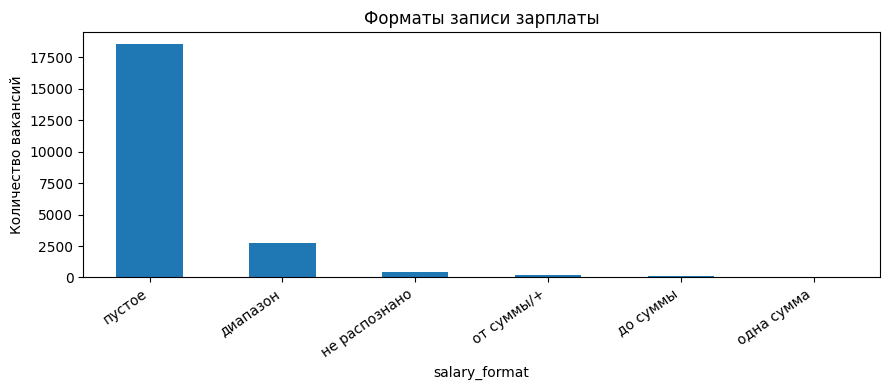

Извлечено числовых сумм, включая нулевые: 3049
Положительных сумм для статистики: 2915
Пустых значений: 18557
Нераспознанных значений: 394
Нулевых минимальных сумм, требующих проверки: 134


In [10]:
# В salary встречаются диапазон, одна сумма, сумма с плюсом и формат Up to.
# Запятая используется как разделитель тысяч, точка — для десятичной части.
amount_pattern = r"(?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)?\s*[kK]?"

salary_prefix = (
    r"(?:(?:expected\s+earnings)|(?:(?:expected\s+)?(?:base\s+)?salary)|"
    r"base\s+pay|pay|compensation|earnings)\s*[:=-]?\s*"
)

range_pattern = re.compile(
    rf"^\s*(?:{salary_prefix})?\$?\s*(?P<low>{amount_pattern})\s*\$?\s*"
    rf"(?:-|–|—|\bto\b)\s*\$?\s*(?P<high>{amount_pattern})\s*\$?(?P<tail>.*)$",
    re.I
)
up_to_pattern = re.compile(
    rf"^\s*up\s+to\s+\$?\s*(?P<amount>{amount_pattern})\s*\$?(?P<tail>.*)$",
    re.I
)
plus_pattern = re.compile(
    rf"^\s*(?:{salary_prefix})?\$?\s*(?P<amount>{amount_pattern})\s*\$?\s*\+\s*(?P<tail>.*)$",
    re.I
)
single_pattern = re.compile(
    rf"^\s*(?:{salary_prefix})?\$?\s*(?P<amount>{amount_pattern})\s*\$?(?P<tail>.*)$",
    re.I
)

period_map = {
    "hour": "hour", "hours": "hour", "hourly": "hour", "hr": "hour", "hrs": "hour",
    "year": "year", "years": "year", "yearly": "year", "yr": "year", "yrs": "year",
    "annual": "year", "annually": "year", "annum": "year",
    "month": "month", "months": "month", "monthly": "month", "mo": "month",
    "week": "week", "weeks": "week", "weekly": "week", "wk": "week", "wks": "week",
    "day": "day"
}

period_slash_pattern = re.compile(
    r"/\s*(hourly|hours?|hrs?|yearly|years?|yrs?|annually|annual|annum|"
    r"monthly|months?|mo|weekly|weeks?|wks?|wk|day)",
    re.I
)
period_per_pattern = re.compile(
    r"\bper\s+(hourly|hours?|hrs?|yearly|years?|yrs?|annually|annual|annum|"
    r"monthly|months?|mo|weekly|weeks?|wks?|wk|day)\b",
    re.I
)
period_word_pattern = re.compile(
    r"\b(hourly|hours?|hrs?|yearly|years?|yrs?|annually|annual|annum|"
    r"monthly|months?|mo|weekly|weeks?|wks?|wk)\b",
    re.I
)


def get_salary_period(text_value):
    match = period_slash_pattern.search(text_value)
    if not match:
        match = period_per_pattern.search(text_value)
    if not match:
        match = period_word_pattern.search(text_value)
    if not match:
        return None
    return period_map.get(match.group(1).lower())


def amount_to_float(value):
    amount = clean_text(value).replace(",", "").replace(" ", "")
    multiplier = 1000 if amount.lower().endswith("k") else 1

    if multiplier == 1000:
        amount = amount[:-1]

    return float(amount) * multiplier


def parse_salary(value):
    if pd.isna(value) or not clean_text(value):
        return (np.nan, np.nan, None, "пустое", "пустое")

    text_value = clean_text(value)
    period = get_salary_period(text_value)
    salary_context = bool(
        re.search(r"\b(salary|base pay|base salary|compensation|earnings)\b", text_value, re.I)
    )

    # Сначала проверяем диапазон.
    match = range_pattern.match(text_value)
    if match:
        low = amount_to_float(match.group("low"))
        high = amount_to_float(match.group("high"))

        if high < low:
            low, high = high, low

        status = "распознано" if low > 0 else "нулевая сумма — проверить"
        return (low, high, period, "диапазон", status)

    # Затем верхнюю границу, обозначенную словами Up to.
    match = up_to_pattern.match(text_value)
    if match:
        amount = amount_to_float(match.group("amount"))
        status = "распознано" if amount > 0 else "нулевая сумма — проверить"
        return (amount, np.nan, period, "до суммы", status)

    # Затем минимальную сумму с плюсом.
    match = plus_pattern.match(text_value)
    if match:
        amount = amount_to_float(match.group("amount"))
        status = "распознано" if amount > 0 else "нулевая сумма — проверить"
        return (amount, np.nan, period, "от суммы/+", status)

    # Дополнительный формат: диапазон часовой ставки внутри текстового описания.
    hourly_range = re.search(
        rf"(?:equal\s+out\s+to|hourly\s+rate.*?to)\s*\$?(?P<low>{amount_pattern})\s*"
        rf"(?:-|to)\s*\$?(?P<high>{amount_pattern})\s*(?:/|per\s+)(?:hour|hr)\b",
        text_value, re.I
    )
    if hourly_range:
        low = amount_to_float(hourly_range.group("low"))
        high = amount_to_float(hourly_range.group("high"))

        if high < low:
            low, high = high, low

        return (low, high, "hour", "диапазон", "распознано")

    # Если сумма одна, по условию задания записываем ее в salary_min.
    match = single_pattern.match(text_value)
    if match:
        amount = amount_to_float(match.group("amount"))
        tail = match.group("tail").strip()
        allowed_tail = not tail or period is not None or salary_context

        if allowed_tail:
            status = "распознано" if amount > 0 else "нулевая сумма — проверить"
            return (amount, np.nan, period, "одна сумма", status)

    return (np.nan, np.nan, period, "не распознано", "не распознано")


salary_parts = pd.DataFrame(
    df["salary"].apply(parse_salary).tolist(),
    columns=["salary_min", "salary_max", "salary_period", "salary_format", "salary_status"],
    index=df.index
)

salary_counts = salary_parts["salary_format"].value_counts()
display(salary_counts.rename_axis("Формат").to_frame("Количество"))

ax = salary_counts.plot.bar(figsize=(9, 4))
ax.set_title("Форматы записи зарплаты")
ax.set_ylabel("Количество вакансий")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("Извлечено числовых сумм, включая нулевые:", int(salary_parts["salary_min"].notna().sum()))
print("Положительных сумм для статистики:", int(salary_parts["salary_status"].eq("распознано").sum()))
print("Пустых значений:", int(salary_parts["salary_format"].eq("пустое").sum()))
print("Нераспознанных значений:", int(salary_parts["salary_format"].eq("не распознано").sum()))
print("Нулевых минимальных сумм, требующих проверки:",
      int(salary_parts["salary_status"].eq("нулевая сумма — проверить").sum()))

#### Задание 2.2

1. Разделите столбец `salary` зарплаты три: `минимальная граница зарплаты`, `максимальная граница зарплаты`, `период`. Если значение суммы указано только одно, считайте, что это минимальная зарплата. Значение суммы в обоих столбцах преобразуйте в формат `float`.
2. Покажите на столбчатой диаграмме с группировкой среднюю и медианную минимальную зарплату в каждом периоде. Сделайте выводы.

Типы salary_min и salary_max: float64 float64


,salary,salary_min,salary_max,salary_period,salary_format,salary_status
13,9.00 - 13.00 $ /hour,9.0,13.0,hour,диапазон,распознано
14,"80,000.00 - 95,000.00 $ /year",80000.0,95000.0,year,диапазон,распознано
19,"60,000.00 - 72,000.00 $ /year",60000.0,72000.0,year,диапазон,распознано
29,"70,000.00 - 100,000.00 $ /year",70000.0,100000.0,year,диапазон,распознано
30,62.00 - 81.00 $ /hour,62.0,81.0,hour,диапазон,распознано
32,"75,000.00 - 100,000.00 $ /year",75000.0,100000.0,year,диапазон,распознано
36,"68,000.00 - 72,000.00 $ /year",68000.0,72000.0,year,диапазон,распознано
41,"58,000.00 - 65,000.00 $ /year",58000.0,65000.0,year,диапазон,распознано
42,Up to $32000.00,32000.0,NaN,None,до суммы,распознано
43,15.00 - 16.00 $ /hour,15.0,16.0,hour,диапазон,распознано


,count,mean,median,minimum,maximum
salary_period,,,,,
day,1,200.00,200.00,200.0,200.00
hour,1085,197.57,16.00,1.0,100000.00
month,17,6048.41,4905.22,1800.0,17688.94
week,7,509.14,600.00,2.0,1100.00
year,1684,62596.34,58250.00,1.0,1000000.00


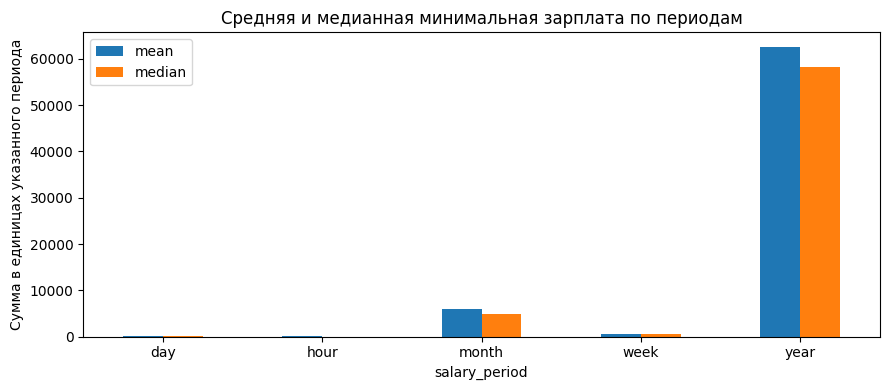

Среднее значение чувствительно к выбросам, поэтому дополнительно смотрим на медиану. Суммы за час, неделю, месяц и год нельзя напрямую сравнивать как одинаковые единицы времени.


In [11]:
salary_data = locations.join(salary_parts)

print(
    "Типы salary_min и salary_max:",
    salary_data["salary_min"].dtype,
    salary_data["salary_max"].dtype
)

display(
    salary_data[
        ["salary", "salary_min", "salary_max", "salary_period", "salary_format", "salary_status"]
    ].loc[salary_data["salary_min"].notna()].head(12)
)

# В статистику включаем только положительные распознанные суммы с известным периодом.
valid_salary = salary_data[
    salary_data["salary_min"].notna()
    & salary_data["salary_status"].eq("распознано")
    & salary_data["salary_period"].notna()
].copy()

salary_stats = (
    valid_salary.groupby("salary_period")["salary_min"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        minimum="min",
        maximum="max"
    )
    .sort_index()
)

display(salary_stats.round(2))

if not salary_stats.empty:
    salary_stats[["mean", "median"]].plot(
        kind="bar",
        figsize=(9, 4),
        title="Средняя и медианная минимальная зарплата по периодам"
    )
    plt.ylabel("Сумма в единицах указанного периода")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

print(
    "Среднее значение чувствительно к выбросам, поэтому дополнительно смотрим на медиану. "
    "Суммы за час, неделю, месяц и год нельзя напрямую сравнивать как одинаковые единицы времени."
)

#### Задание 2.3

Период оплаты может отсутствовать. Для восстановления:
1. Считаем разброс значений для каждого известного периода.
2. Строим гистограмму для каждого периода.
3. Находим выбросы по правилу `1,5 × IQR`, где `IQR = Q3 - Q1`.
4. Для сравнения используем среднее значение без выбросов, чтобы несколько экстремальных сумм не смещали ориентир.
5. Сумму с неизвестным периодом относим к периоду с ближайшим средним. Если два ближайших варианта почти одинаково близки (разница расстояний не более 5%), период не назначаем.

Период с менее чем пятью наблюдениями показываем на гистограмме, но не используем для автоматического восстановления.


,count,minimum,maximum,mean,median,outliers,mean_without_outliers,count_without_outliers
period,,,,,,,,
day,1,200.0,200.00,200.00,200.00,0,200.00,1
hour,1085,1.0,100000.00,197.57,16.00,86,17.66,999
month,17,1800.0,17688.94,6048.41,4905.22,2,4496.34,15
week,7,2.0,1100.00,509.14,600.00,0,509.14,7
year,1684,1.0,1000000.00,62596.34,58250.00,31,58636.56,1653


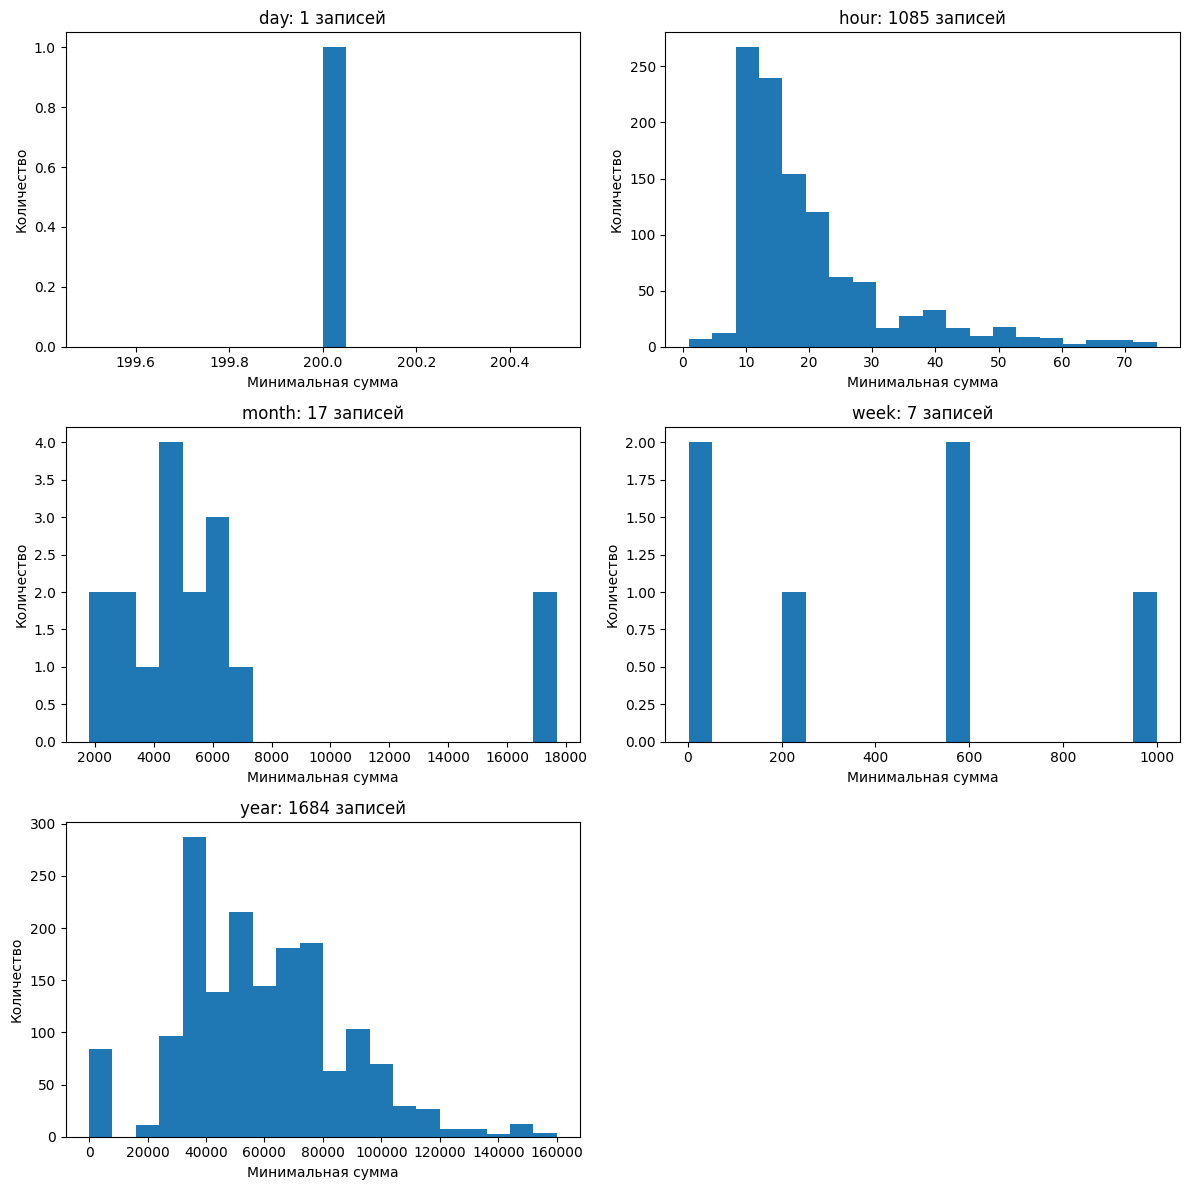

Для выявления выбросов использовано правило 1,5 межквартильного размаха (IQR). Выбросы не удаляются из исходного датасета: для оценки типичной суммы дополнительно рассчитывается среднее без выбросов.
Записей с суммой, но без исходного периода: 121
Период восстановлен: 114
Неоднозначных случаев: 7


,salary,salary_min,salary_period_final,period_inferred,period_inference_status
42,Up to $32000.00,32000.0,None,False,неоднозначно: year/month
154,Up to $45000.00,45000.0,year,True,определён по ближайшему среднему
2424,"108,887.00 - 141,555.00",108887.0,year,True,определён по ближайшему среднему
2630,Up to $18.00,18.0,hour,True,определён по ближайшему среднему
2639,Up to $13.00,13.0,hour,True,определён по ближайшему среднему
2651,Up to $18.00,18.0,hour,True,определён по ближайшему среднему
2655,Up to $14.00,14.0,hour,True,определён по ближайшему среднему
2669,Up to $18.00,18.0,hour,True,определён по ближайшему среднему
2717,Up to $15.00,15.0,hour,True,определён по ближайшему среднему
2792,Up to $30000.00,30000.0,month,True,определён по ближайшему среднему


In [12]:
# Сначала оцениваем разброс и выбросы отдельно для каждого периода.
period_rows = []

for period, group in valid_salary.groupby("salary_period"):
    values = group["salary_min"]

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = max(0, q1 - 1.5 * iqr)
    upper_bound = q3 + 1.5 * iqr

    values_without_outliers = values[
        values.between(lower_bound, upper_bound)
    ]

    period_rows.append({
        "period": period,
        "count": len(values),
        "minimum": values.min(),
        "maximum": values.max(),
        "mean": values.mean(),
        "median": values.median(),
        "outliers": len(values) - len(values_without_outliers),
        "mean_without_outliers": values_without_outliers.mean(),
        "count_without_outliers": len(values_without_outliers)
    })

salary_period_stats = pd.DataFrame(period_rows).set_index("period").sort_index()
display(salary_period_stats.round(2))

# Строим отдельную гистограмму для каждого периода.
period_names = salary_period_stats.index.tolist()
column_count = 2
row_count = int(np.ceil(len(period_names) / column_count))

fig, axes = plt.subplots(row_count, column_count, figsize=(12, 4 * row_count))
axes = np.array(axes).reshape(-1)

for number, period in enumerate(period_names):
    values = valid_salary.loc[
        valid_salary["salary_period"].eq(period), "salary_min"
    ]

    # Ограничиваем только отображение графика 99-м перцентилем.
    # Исходные значения и выбросы из таблицы не удаляются.
    upper_for_plot = values.quantile(0.99)
    values_for_plot = values[values <= upper_for_plot]

    if values_for_plot.empty:
        values_for_plot = values

    axes[number].hist(values_for_plot, bins=20)
    axes[number].set_title(f"{period}: {len(values)} записей")
    axes[number].set_xlabel("Минимальная сумма")
    axes[number].set_ylabel("Количество")

for number in range(len(period_names), len(axes)):
    axes[number].set_visible(False)

plt.tight_layout()
plt.show()

print(
    "Для выявления выбросов использовано правило 1,5 межквартильного размаха (IQR). "
    "Выбросы не удаляются из исходного датасета: для оценки типичной суммы "
    "дополнительно рассчитывается среднее без выбросов."
)

# Для вывода периода используем средние без выбросов.
# Период с менее чем пятью наблюдениями не используем для автоматического определения.
period_means = salary_period_stats.loc[
    salary_period_stats["count"] >= 5, "mean_without_outliers"
].to_dict()

unknown_salary_mask = (
    salary_data["salary_min"].notna()
    & salary_data["salary_status"].eq("распознано")
    & salary_data["salary_period"].isna()
)

unknown_salary_values = salary_data.loc[unknown_salary_mask, "salary_min"]

salary_data["salary_period_final"] = salary_data["salary_period"].where(
    salary_data["salary_min"].notna()
)
salary_data["period_inferred"] = False
salary_data["period_inference_status"] = "не применимо"

salary_data.loc[
    salary_data["salary_format"].eq("пустое"),
    "period_inference_status"
] = "пустая запись"

salary_data.loc[
    salary_data["salary_status"].eq("не распознано"),
    "period_inference_status"
] = "не распознано"

salary_data.loc[
    salary_data["salary_status"].eq("нулевая сумма — проверить"),
    "period_inference_status"
] = "сумма требует проверки"

known_period_mask = (
    salary_data["salary_status"].eq("распознано")
    & salary_data["salary_period"].notna()
)

salary_data.loc[
    known_period_mask,
    "period_inference_status"
] = "указан в исходных данных"

salary_data.loc[
    unknown_salary_mask,
    "period_inference_status"
] = "не определён"

inference_rows = []

for index, amount in unknown_salary_values.items():
    distances = sorted(
        (abs(amount - mean), period)
        for period, mean in period_means.items()
    )

    if len(distances) < 2:
        continue

    best_distance, best_period = distances[0]
    second_distance, second_period = distances[1]

    # Если два ближайших варианта отличаются по расстоянию не более чем на 5%,
    # считаем результат спорным и не назначаем период.
    ambiguous = (
        abs(second_distance - best_distance)
        <= 0.05 * max(second_distance, 1)
    )

    if ambiguous:
        inference_rows.append((index, None, f"неоднозначно: {best_period}/{second_period}"))
    else:
        inference_rows.append((index, best_period, "определён по ближайшему среднему"))

for index, inferred_period, status in inference_rows:
    if inferred_period is not None:
        salary_data.at[index, "salary_period_final"] = inferred_period
        salary_data.at[index, "period_inferred"] = True

    salary_data.at[index, "period_inference_status"] = status

print("Записей с суммой, но без исходного периода:", len(unknown_salary_values))
print("Период восстановлен:", int(salary_data["period_inferred"].sum()))
print(
    "Неоднозначных случаев:",
    int(salary_data["period_inference_status"].str.startswith("неоднозначно").sum())
)

display(
    salary_data.loc[
        unknown_salary_mask,
        ["salary", "salary_min", "salary_period_final", "period_inferred", "period_inference_status"]
    ].head(15)
)

### Задание 3

В задании 3 необходимо провести обработку столбца `job_type`. Выясните, какие форматы значений есть в столбце `job_type`. Сделайте выводы. При необходимости – стройте графики.

In [13]:
# Сначала смотрим на исходные значения без нормализации.
raw_job_types = df["job_type"].astype("string")

print("Варианты в исходном job_type:")
display(raw_job_types.value_counts(dropna=False).head(40).to_frame("Количество"))

print("Количество различных непустых исходных вариантов:", raw_job_types.nunique(dropna=True))
print(
    "Проблемы: разные регистры, пробелы, дефисы и разделители; "
    "встречаются неполные записи и дополнительные типы занятости."
)

Варианты в исходном job_type:


,Количество
job_type,
Full Time,6757
Full Time Employee,6617
"Full Time, Employee",3360
<NA>,1628
Full Time Temporary/Contract/Project,1062
"Full Time, Temporary/Contract/Project",533
"Full Time , Employee",406
Part Time Employee,382
Part Time,329


Количество различных непустых исходных вариантов: 39
Проблемы: разные регистры, пробелы, дефисы и разделители; встречаются неполные записи и дополнительные типы занятости.


Вы заметили, что многие значения фактически одинаковые, но немного по-разному отформатированы? Приведем их к единому формату.

In [14]:
# Приводим регистр, пробелы и разделители к одному виду.
job_type_normalized = (
    raw_job_types.str.lower()
    .str.replace(r"[-_/;,]+", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

display(
    pd.DataFrame({
        "До": raw_job_types,
        "После": job_type_normalized
    }).drop_duplicates().head(30)
)

print("Уникальных исходных вариантов:", raw_job_types.nunique(dropna=True))
print("После нормализации:", job_type_normalized.nunique(dropna=True))

,До,После
0,Full Time Employee,full time employee
1,Full Time,full time
2,"Full Time, Employee",full time employee
8,Part Time Employee,part time employee
9,<NA>,<NA>
21,Full Time Temporary/Contract/Project,full time temporary contract project
82,"Full Time , Employee",full time employee
90,"Full Time, Temporary/Contract/Project",full time temporary contract project
129,Employee,employee
136,Part Time,part time


Уникальных исходных вариантов: 39
После нормализации: 21


Столбец `job_type` состоит из двух основных частей: полнота занятости (`Full Time`, `Part Time`, `Per Diem`) и тип найма (`Employee`, `Intern`). В данных также встречаются явно записанные дополнительные варианты: `Temporary/Contract/Project`, `Seasonal` и `Exempt`.

**Правило обработки:** если часть действительно отсутствует, используем значения по умолчанию из задания: `Full Time` для полноты и `Employee` для типа. Явно указанные дополнительные категории не заменяем на `Employee`, чтобы не терять информацию.


,Количество
job_type_status,
распознано,12905
частично заполнено по умолчанию,7467
оба значения по умолчанию,1628


employment_type,Employee,Exempt,Intern,Seasonal,Temporary/Contract/Project
work_schedule,,,,,
Full Time,19087,1,5,0,1847
Part Time,916,0,3,17,57
Per Diem,63,0,0,0,4


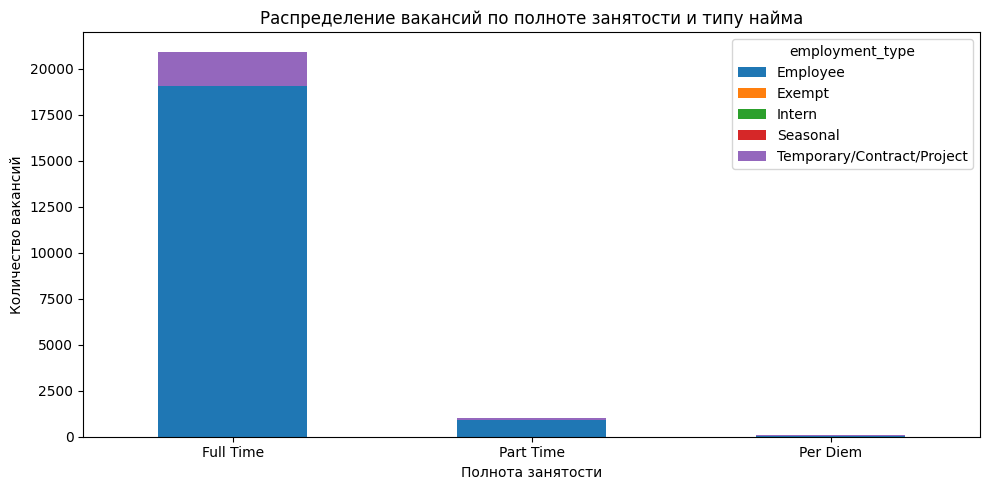

В исходных данных, кроме Employee и Intern, явно встречаются Temporary/Contract/Project, Seasonal и Exempt. Мы сохраняем эти значения отдельно, а Employee подставляем только тогда, когда тип действительно отсутствует.


Итоговый очищенный CSV: monster_jobs_cleaned_lab2.csv | строк: 22000 | столбцов: 30


,location,city,state_code,zip_code,salary,salary_min,salary_max,salary_period_final,job_type,work_schedule,employment_type
0,"Madison, WI 53702",Madison,WI,53702,NaN,NaN,NaN,NaN,Full Time Employee,Full Time,Employee
1,"Madison, WI 53708",Madison,WI,53708,NaN,NaN,NaN,NaN,Full Time,Full Time,Employee
2,"DePuy Synthes Companies is a member of Johnson & Johnson's Family of Companies, and is...",Raynham,MA,None,NaN,NaN,NaN,NaN,"Full Time, Employee",Full Time,Employee
3,"Dixon, CA",Dixon,CA,None,NaN,NaN,NaN,NaN,Full Time,Full Time,Employee
4,"Camphill, PA",Camphill,PA,None,NaN,NaN,NaN,NaN,Full Time Employee,Full Time,Employee
5,"Charlottesville, VA",Charlottesville,VA,None,NaN,NaN,NaN,NaN,Full Time Employee,Full Time,Employee
6,Contact name Tony Zerio,Contact name Tony Zerio,None,None,NaN,NaN,NaN,NaN,"Full Time, Employee",Full Time,Employee
7,"Austin, TX 73301",Austin,TX,73301,NaN,NaN,NaN,NaN,Full Time Employee,Full Time,Employee


In [15]:
schedule_patterns = {
    "Full Time": re.compile(r"\bfull\s*time\b|\bfulltime\b", re.I),
    "Part Time": re.compile(r"\bpart\s*time\b|\bparttime\b", re.I),
    "Per Diem": re.compile(r"\bper\s*diem\b", re.I)
}

employment_patterns = {
    "Employee": re.compile(r"\bemployee\b", re.I),
    "Intern": re.compile(r"\b(?:intern|internship|trainee)\b", re.I),
    "Temporary/Contract/Project": re.compile(r"\btemporary\s+contract\s+project\b", re.I),
    "Seasonal": re.compile(r"\bseasonal\b", re.I),
    "Exempt": re.compile(r"\bexempt\b", re.I)
}


def parse_job_type(value):
    if pd.isna(value) or not clean_text(value):
        return ("Full Time", "Employee", "оба значения по умолчанию")

    text_value = clean_text(value).lower()
    text_value = re.sub(r"^job\s+type\s*", "", text_value)
    text_value = re.sub(r"[-_/;,]+", " ", text_value)
    text_value = re.sub(r"\s+", " ", text_value).strip()

    schedule_found = [
        name for name, pattern in schedule_patterns.items()
        if pattern.search(text_value)
    ]
    employment_found = [
        name for name, pattern in employment_patterns.items()
        if pattern.search(text_value)
    ]

    if len(schedule_found) > 1 or len(employment_found) > 1:
        return (None, None, "конфликтующие категории")

    # Удаляем распознанные слова и проверяем, не осталось ли неизвестного текста.
    remaining_text = text_value

    for pattern in schedule_patterns.values():
        remaining_text = pattern.sub(" ", remaining_text)

    for pattern in employment_patterns.values():
        remaining_text = pattern.sub(" ", remaining_text)

    remaining_text = re.sub(r"\bjob\s+type\b", " ", remaining_text)
    remaining_text = re.sub(r"[^a-z]+", " ", remaining_text).strip()

    if remaining_text:
        return (
            schedule_found[0] if schedule_found else None,
            employment_found[0] if employment_found else None,
            "не распознано"
        )

    # Правила по умолчанию из задания.
    schedule = schedule_found[0] if schedule_found else "Full Time"
    employment = employment_found[0] if employment_found else "Employee"

    if not schedule_found and not employment_found:
        status = "оба значения по умолчанию"
    elif not schedule_found or not employment_found:
        status = "частично заполнено по умолчанию"
    else:
        status = "распознано"

    return (schedule, employment, status)


job_type_parts = pd.DataFrame(
    df["job_type"].apply(parse_job_type).tolist(),
    columns=["work_schedule", "employment_type", "job_type_status"],
    index=df.index
)

display(job_type_parts["job_type_status"].value_counts().to_frame("Количество"))
display(pd.crosstab(job_type_parts["work_schedule"], job_type_parts["employment_type"]))

job_type_table = pd.crosstab(
    job_type_parts["work_schedule"],
    job_type_parts["employment_type"]
)

if not job_type_table.empty:
    job_type_table.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 5),
        title="Распределение вакансий по полноте занятости и типу найма"
    )
    plt.ylabel("Количество вакансий")
    plt.xlabel("Полнота занятости")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

print(
    "В исходных данных, кроме Employee и Intern, явно встречаются "
    "Temporary/Contract/Project, Seasonal и Exempt. Мы сохраняем эти значения "
    "отдельно, а Employee подставляем только тогда, когда тип действительно отсутствует."
)

# Объединяем исходные и обработанные поля, не удаляя оригинальные столбцы.
result = salary_data.join(job_type_parts)

output_name = "monster_jobs_cleaned_lab2.csv"
result.to_csv(output_name, index=False)

print(
    "Итоговый очищенный CSV:",
    output_name,
    "| строк:",
    len(result),
    "| столбцов:",
    len(result.columns)
)

display(
    result[
        [
            "location", "city", "state_code", "zip_code",
            "salary", "salary_min", "salary_max", "salary_period_final",
            "job_type", "work_schedule", "employment_type"
        ]
    ].head(8)
)

# Порядок защиты работы

**Для защиты работы необходимо:**
1. Предоставить результаты выполнения всех заданий в виде ссылки на Google Colab в новой ветке своего репозитория по первой лабораторной на GitHub. Открыть `pull request`.
2. Выполнить дополнительное задание в процессе сдачи работы. Дополнительное задание представляет собой решение задачи на обработку данных лабораторной работы, меньшее по объему, но сопоставимое по сложности тем заданиям, которые требовалось выполнить в рамках работы.

**Примеры дополнительных заданий:**
1. В столбце `sector` часто представлены данные из столбца `organization` и наоборот. Устраните эту проблему.
2. В столбце `job_title` часто можно частично или полностью встретить указание местоположения организации. Сравните, совпадают ли в таких случаях данные с тем, что указано в столбцах `город`, `код штата`, `почтовый индекс`. Если в этих трех столбцах данные отсутствуют, заполните их данными из столбца `job_title`.
3. Практически во всех столбцах датасета вместо соответствующих названию данных иногда встречается текст из `job_description`. Найдите такие столбцы и записи с описанием вакансии в них. Покажите на столбчатой диаграмме, в каких столбцах и в каком количестве находится информация из столбца `job_description`.

# Дополнительные материалы

1. DAMA-DMBOK: Свод знаний по управлению данными: Второе издание / DAMA International; [пер. с англ.]. – Москва: ООО "Олимп-Бизнес", 2021. – 828 с.
2. Макгрегор, С. Обработка данных на Python: Data Wrangling и Data Quality: [Текст] / С. Макгрегор. – Москва: БХВ, 2024. – 432 с.

## Итоговый вывод

На исходном наборе из 22 000 вакансий и 14 столбцов выполнена первичная проверка качества и обработка трёх полей.

- В строках нет случаев, где пустыми являются более 75% ячеек. Однако после удаления всех строк хотя бы с одним пропуском остаётся только 5 записей, поэтому массовое удаление строк не подходит.
- Найдены 4 столбца с единственным непустым значением: `country`, `country_code`, `has_expired`, `job_board`. Полностью уникальными являются `page_url` и `uniq_id`.
- После исключения уникальных столбцов найдено 910 групп повторяющихся строк: в них участвуют 2 078 записей, включая 1 168 повторных вхождений сверх первого.
- В `location` выделены сочетания города, штата и индекса. Самый частый формат — город + штат + индекс. В 2 005 строках исходный формат не удалось определить автоматически; в 346 из них удалось извлечь хотя бы один признак по явным меткам или структуре текста.
- В `salary` распознаны числовые значения и периоды. 134 записи с нулевой минимальной суммой оставлены для проверки. Для 121 положительной суммы период отсутствовал: 114 периодов определены по ближайшему среднему, а 7 спорных случаев оставлены без предположения.
- В `job_type` 39 исходных вариантов после нормализации сведены к 21 написанию. Для отсутствующих частей применены значения по умолчанию, а явно указанные дополнительные категории сохранены.

Исходные столбцы не удалялись и не перезаписывались. В конце создаётся `monster_jobs_cleaned_lab2.csv` с оригинальными и добавленными обработанными полями.


## Мини-шпаргалка перед защитой

- `isna()` и проверка строк из пробелов — поиск пустых ячеек.
- `nunique(dropna=True)` — число уникальных непустых значений.
- `duplicated(subset=..., keep=False)` — все строки, входящие в группы дубликатов.
- `re.compile`, `search`, `match`, `finditer` — регулярные выражения для распознавания форматов.
- `groupby().agg()` — среднее, медиана, минимум и максимум по периодам.
- `IQR = Q3 - Q1`; границы выбросов — `Q1 - 1.5 × IQR` и `Q3 + 1.5 × IQR`.
- `pd.crosstab()` + `plot(stacked=True)` — сводная таблица и составная диаграмма по категориям.
- `salary_period_final` — исходный период или осторожно восстановленный; спорные случаи остаются пустыми.
- `location_recovery_status` и `job_type_status` показывают, откуда появились обработанные значения.

**Как сдавать:** по условию этой лабораторной нужно предоставить ссылку на Google Colab в новой ветке репозитория по первой лабораторной и открыть Pull Request. Перед отправкой выполните все ячейки и убедитесь, что построились графики и создался итоговый CSV.
